In [ ]:
# !pip uninstall llama-cpp-python -y
!pip install llama-cpp-python -q
from huggingface_hub import hf_hub_download
from llama_cpp import Llama
import os

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.0/68.0 MB 10.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.4 MB/s eta 0:00:00


In [ ]:
model_path = hf_hub_download(
    repo_id="TheBloke/Mistral-7B-Instruct-v0.2-GGUF",
    filename="mistral-7b-instruct-v0.2.Q4_K_M.gguf"
)
print(f"Downloaded: {model_path}")

# Step 2 — load model
llm = Llama(
    model_path=model_path,
    n_ctx=4096,          #WAS 4096
    n_threads=os.cpu_count(),
    n_batch=512,          #WAS 512
    verbose=False
)

print("Mistral 7B loaded")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


mistral-7b-instruct-v0.2.Q4_K_M.gguf:   0%|          | 0.00/4.37G [00:00<?, ?B/s]

Downloaded: /root/.cache/huggingface/hub/models--TheBloke--Mistral-7B-Instruct-v0.2-GGUF/snapshots/3a6fbf4a41a1d52e415a4958cde6856d34b2db93/mistral-7b-instruct-v0.2.Q4_K_M.gguf


llama_context: n_ctx_seq (4096) < n_ctx_train (32768) -- the full capacity of the model will not be utilized


Mistral 7B loaded


In [ ]:
import pandas as pd

df = pd.read_csv("requirements_dataset.csv")
from sklearn.model_selection import train_test_split

# Stratified split — preserves class balance in both sets
prompt_dev_df, eval_df = train_test_split(
    df,
    test_size=0.75,        # 75% for evaluation, 25% for prompt dev
    stratify=df["DetectedAs"],  # keeps AMBIGUOUS/CLEAR ratio the same in both
    random_state=42
)

print(f"Prompt dev set : {len(prompt_dev_df)}")
print(f"Evaluation set : {len(eval_df)}")
print("\nPrompt dev label distribution:")
print(prompt_dev_df["DetectedAs"].value_counts())
print("\nEvaluation label distribution:")
print(eval_df["DetectedAs"].value_counts())

# Save them separately so you don't accidentally mix them
prompt_dev_df.to_csv("prompt_dev.csv", index=False)
eval_df.to_csv("eval_set.csv", index=False)

Prompt dev set : 184
Evaluation set : 553

Prompt dev label distribution:
DetectedAs
unambiguous    99
ambiguous      85
Name: count, dtype: int64

Evaluation label distribution:
DetectedAs
unambiguous    296
ambiguous      257
Name: count, dtype: int64


In [ ]:
# load pronoun dataset and set up embedder
from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd

# Load dataset as the example pool
examples_df = prompt_dev_df.copy()
# If columns are "Context" and "DetectedAs" rename first
examples_df = examples_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})
print(f"Example pool: {len(examples_df)} requirements")
print(examples_df["label"].value_counts())

# Load embedder
embedder = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")

# Encode all examples once
print("Encoding example pool...")
example_embeddings = embedder.encode(
    examples_df["requirement"].tolist(),
    show_progress_bar=True
)
print("Done encoding.")

Example pool: 184 requirements
label
unambiguous    99
ambiguous      85
Name: count, dtype: int64


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoding example pool...


Batches:   0%|          | 0/6 [00:00<?, ?it/s]

Done encoding.


In [ ]:
# retrieval function
def retrieve_similar_examples(requirement: str, n: int = 5) -> pd.DataFrame:
    query_vec = embedder.encode([requirement])
    similarities = np.dot(example_embeddings, query_vec.T).flatten()
    top_indices = similarities.argsort()[-n:][::-1]
    return examples_df.iloc[top_indices]


prompt 1 - Basic prompt

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.

A requirement is ambiguous if it introduces real uncertainty in understanding:
- Vague terms with no measurable threshold (e.g., "quickly", "efficiently")
- Unclear pronoun references
- Multiple reasonable interpretations
- Unclear scope or responsibility

A requirement is unambiguous if meaning is clear to an engineer.

Here are similar requirements for reference:

{examples_block}Classify this requirement:
"{req}"

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_results(dev_results, model_name: str):
    # Normalise both columns to uppercase
    dev_results["predicted_clean"]    = dev_results["predicted"].str.strip().str.upper()
    dev_results["ground_truth_clean"] = dev_results["ground_truth"].str.strip().str.upper()

    # Filter errors
    clean = dev_results[dev_results["predicted_clean"] != "ERROR"].copy()
    print(f"\n========== {model_name} ==========")
    print(f"Valid predictions : {len(clean)}")
    print(f"Errors            : {len(dev_results) - len(clean)}")

    y_true = clean["ground_truth_clean"]
    y_pred = clean["predicted_clean"]

    print(f"\nAccuracy: {accuracy_score(y_true, y_pred):.4f}")
    print("\n" + classification_report(
        y_true, y_pred,
        labels=["AMBIGUOUS", "UNAMBIGUOUS"],
        target_names=["AMBIGUOUS", "UNAMBIGUOUS"]
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=["AMBIGUOUS", "UNAMBIGUOUS"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["AMBIGUOUS", "UNAMBIGUOUS"],
                yticklabels=["AMBIGUOUS", "UNAMBIGUOUS"])
    plt.xlabel("Predicted")
    plt.ylabel("Ground Truth")
    plt.title(f"{model_name} — confusion matrix")
    plt.tight_layout()
    plt.show()

    return accuracy_score(y_true, y_pred)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:27:31<00:00, 175.06s/it]


Done. Errors: 0

========== Mistral 7B — RAG pronoun 5-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.4667

              precision    recall  f1-score   support

   AMBIGUOUS       0.41      1.00      0.58        11
 UNAMBIGUOUS       1.00      0.16      0.27        19

    accuracy                           0.47        30
   macro avg       0.70      0.58      0.43        30
weighted avg       0.78      0.47      0.39        30



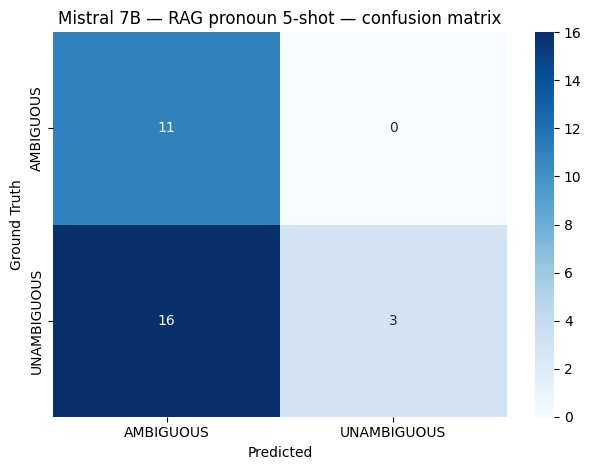

0.4666666666666667

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=5
)

# dev_results_rag_pronoun = run_evaluation_rag_fast(
#     prompt_dev_df,
#     model_type="qwen",
#     model_name="mistral7b",
#     n_examples=5
# )

evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 5-shot")

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=100, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=5
)

Encoding all query requirements...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 100/100 [5:00:17<00:00, 180.17s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 5-shot ==========
Valid predictions : 100
Errors            : 0

Accuracy: 0.5200

              precision    recall  f1-score   support

   AMBIGUOUS       0.48      1.00      0.65        45
 UNAMBIGUOUS       1.00      0.13      0.23        55

    accuracy                           0.52       100
   macro avg       0.74      0.56      0.44       100
weighted avg       0.77      0.52      0.42       100



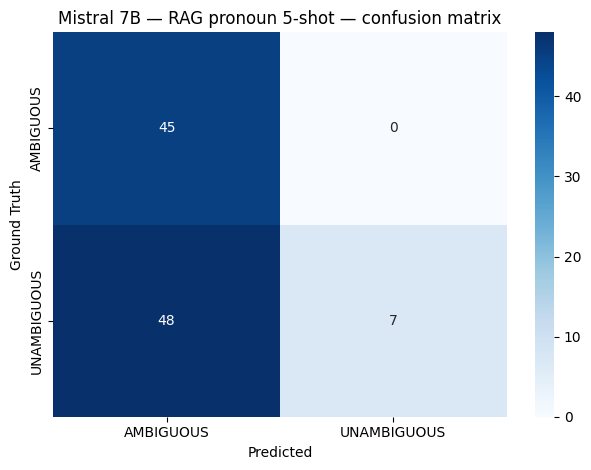

0.52

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 5-shot")

Prompt 2 - Conservative — default UNAMBIGUOUS

In [ ]:


from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.

Most requirements written by engineers are UNAMBIGUOUS. Only classify as AMBIGUOUS if there is a CLEAR and SPECIFIC problem.

A requirement is AMBIGUOUS ONLY if it has at least ONE of these specific problems:
- A vague term with NO measurable threshold (e.g. "quickly", "efficiently", "soon") — NOT just any adjective
- A pronoun (it/they/this) where it is genuinely unclear what it refers to
- Two or more completely different valid interpretations that would lead to different implementations

A requirement is UNAMBIGUOUS if:
- An engineer can implement it without needing to ask clarifying questions
- Terms may be technical but have accepted domain meanings
- It is specific about what, who, and when even if not perfectly worded

When in doubt, classify as UNAMBIGUOUS.

Here are similar requirements for reference:

{examples_block}Classify this requirement:
"{req}"

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=5
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:32:36<00:00, 185.22s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 5-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.4667

              precision    recall  f1-score   support

   AMBIGUOUS       0.37      0.64      0.47        11
 UNAMBIGUOUS       0.64      0.37      0.47        19

    accuracy                           0.47        30
   macro avg       0.50      0.50      0.47        30
weighted avg       0.54      0.47      0.47        30



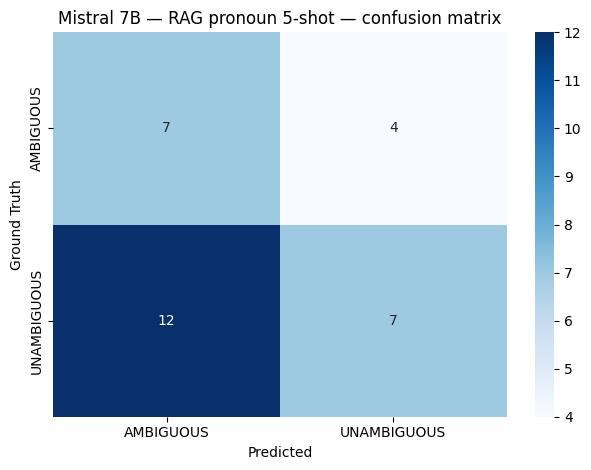

0.4666666666666667

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 5-shot")

Prompt 3 - Balanced retrieval + conservative

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        # top_indices = sim_scores.argsort()[-n_examples:][::-1]
        # similar = examples_df.iloc[top_indices]
        # balanced retrieval ───────────
        sorted_indices = sim_scores.argsort()[::-1]

        amb_indices   = [idx for idx in sorted_indices
                        if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        unamb_indices = [idx for idx in sorted_indices
                        if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.

Most requirements written by engineers are UNAMBIGUOUS. Only classify as AMBIGUOUS if there is a CLEAR and SPECIFIC problem.

A requirement is AMBIGUOUS ONLY if it has at least ONE of these specific problems:
- A vague term with NO measurable threshold (e.g. "quickly", "efficiently", "soon") — NOT just any adjective
- A pronoun (it/they/this) where it is genuinely unclear what it refers to
- Two or more completely different valid interpretations that would lead to different implementations

A requirement is UNAMBIGUOUS if:
- An engineer can implement it without needing to ask clarifying questions
- Terms may be technical but have accepted domain meanings
- It is specific about what, who, and when even if not perfectly worded

When in doubt, classify as UNAMBIGUOUS.

Here are similar requirements for reference:

{examples_block}Classify this requirement:
"{req}"

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=6
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:41:04<00:00, 202.14s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 5-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.4000

              precision    recall  f1-score   support

   AMBIGUOUS       0.36      0.82      0.50        11
 UNAMBIGUOUS       0.60      0.16      0.25        19

    accuracy                           0.40        30
   macro avg       0.48      0.49      0.38        30
weighted avg       0.51      0.40      0.34        30



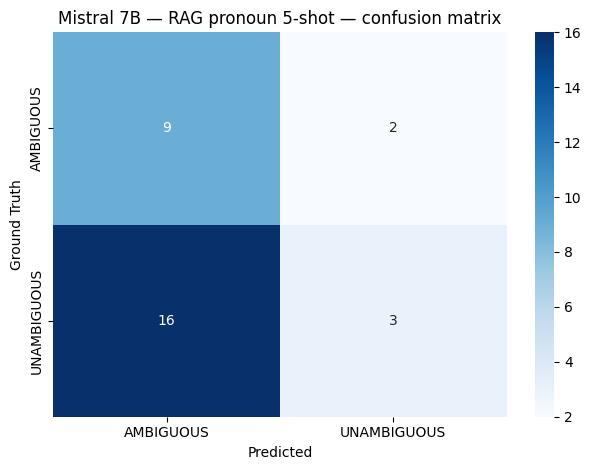

0.4

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 5-shot")

Prompt 4 - Pronoun ambiguity focused

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis specialising in pronoun ambiguity.

A requirement has PRONOUN AMBIGUITY if:
- A pronoun (it, they, them, their, this, these, those, its) appears AND
- It is genuinely unclear which noun it refers to because multiple candidates exist

A requirement is UNAMBIGUOUS if:
- All pronouns clearly refer to one specific noun with no doubt
- There are no pronouns, OR pronouns have only one possible referent
- The requirement is clear enough for an engineer to implement without asking questions

Examples:
{examples_block}
Does this requirement contain pronoun ambiguity?
"{req}"

Think step by step:
1. Identify any pronouns in the requirement
2. For each pronoun, list the possible referents
3. If any pronoun has 2+ possible referents → AMBIGUOUS, else → UNAMBIGUOUS

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=6
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [2:07:54<00:00, 255.80s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 5-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.4000

              precision    recall  f1-score   support

   AMBIGUOUS       0.35      0.73      0.47        11
 UNAMBIGUOUS       0.57      0.21      0.31        19

    accuracy                           0.40        30
   macro avg       0.46      0.47      0.39        30
weighted avg       0.49      0.40      0.37        30



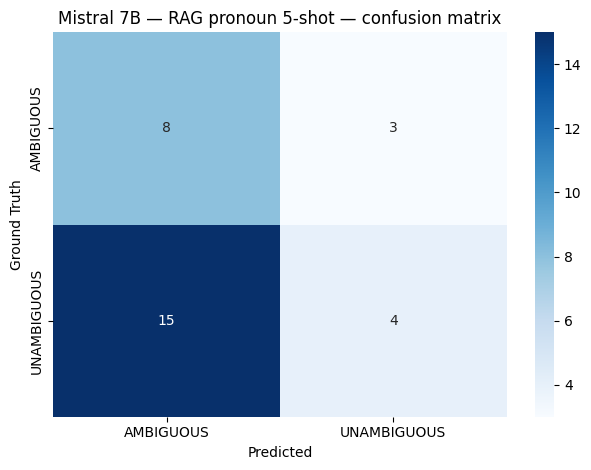

0.4

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 5-shot")

Prompt 5 - Balanced wording

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""
You are an expert in software requirement analysis.
A requirement is ambiguous if it introduces real uncertainty in understanding
A requirement is ambiguous if:
- It uses vague terms (e.g., "quickly", "efficiently") that affect interpreta
- It has unclear pronoun references (e.g., "it", "they")
- It allows multiple reasonable interpretations
A requirement is NOT ambiguous if:
- It is understandable by an engineer
- It follows standard engineering wording
- It contains general terms that do not affect implementation
IMPORTANT:
- Do NOT classify as ambiguous for minor wording issues
- Do NOT classify as ambiguous just because the sentence is complex
- Do NOT ignore clear ambiguity
Be balanced:
- If ambiguity clearly affects understanding → ambiguous
- Otherwise → unambiguous
Examples:
{examples_block}
Classify this requirement:
"{req}"

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [57:51<00:00, 115.71s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 5-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.5667

              precision    recall  f1-score   support

   AMBIGUOUS       0.44      0.73      0.55        11
 UNAMBIGUOUS       0.75      0.47      0.58        19

    accuracy                           0.57        30
   macro avg       0.60      0.60      0.57        30
weighted avg       0.64      0.57      0.57        30



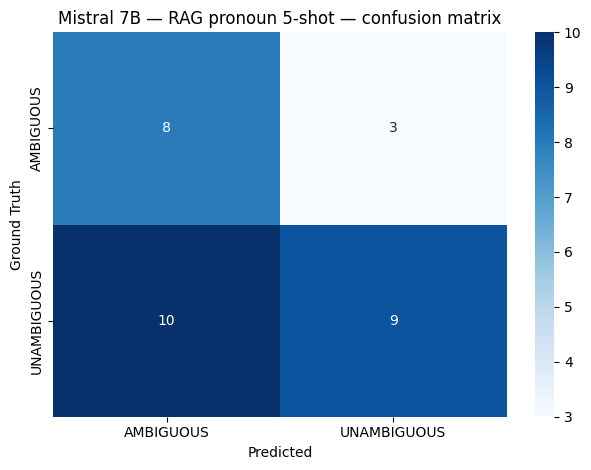

0.5666666666666667

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 5-shot")

prompt5 -100

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""
You are an expert in software requirement analysis.
A requirement is ambiguous if it introduces real uncertainty in understanding
A requirement is ambiguous if:
- It uses vague terms (e.g., "quickly", "efficiently") that affect interpreta
- It has unclear pronoun references (e.g., "it", "they")
- It allows multiple reasonable interpretations
A requirement is NOT ambiguous if:
- It is understandable by an engineer
- It follows standard engineering wording
- It contains general terms that do not affect implementation
IMPORTANT:
- Do NOT classify as ambiguous for minor wording issues
- Do NOT classify as ambiguous just because the sentence is complex
- Do NOT ignore clear ambiguity
Be balanced:
- If ambiguity clearly affects understanding → ambiguous
- Otherwise → unambiguous

Examples:
{examples_block}
Classify this requirement:
"{req}"

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=100, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 100/100 [3:54:10<00:00, 140.50s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 5-shot ==========
Valid predictions : 100
Errors            : 0

Accuracy: 0.5800

              precision    recall  f1-score   support

   AMBIGUOUS       0.52      0.87      0.65        45
 UNAMBIGUOUS       0.76      0.35      0.47        55

    accuracy                           0.58       100
   macro avg       0.64      0.61      0.56       100
weighted avg       0.65      0.58      0.55       100



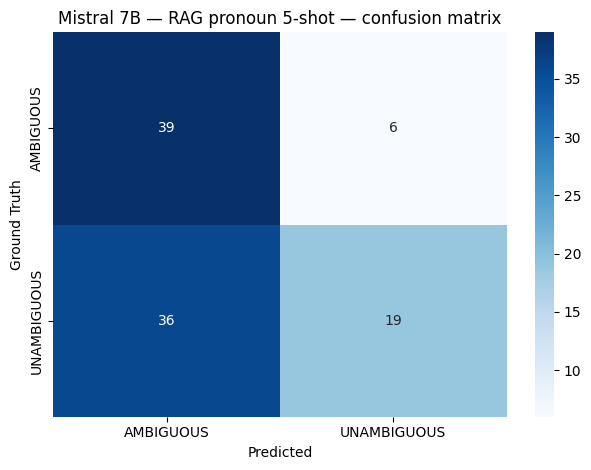

0.58

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 5-shot")

Prompt 6 - Self-check + default UNAMBIGUOUS

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""
You are an expert in software requirement analysis.
A requirement is ambiguous if it introduces real uncertainty in understanding
A requirement is ambiguous if:
- It uses vague terms (e.g., "quickly", "efficiently") that affect interpreta
- It has unclear pronoun references (e.g., "it", "they")
- It allows multiple reasonable interpretations
A requirement is NOT ambiguous if:
- It is understandable by an engineer
- It follows standard engineering wording
- It contains general terms that do not affect implementation
IMPORTANT:
- Do NOT classify as ambiguous for minor wording issues
- Do NOT classify as ambiguous just because the sentence is complex
- Do NOT ignore clear ambiguity
Be balanced:
- If ambiguity clearly affects understanding → ambiguous
- Otherwise → unambiguous
BEFORE classifying, ask yourself:
- Would two engineers implement this differently? If NO → UNAMBIGUOUS
- Is there a specific vague word that has no measurable threshold? If NO → UNAMBIGUOUS
- Is there a pronoun with genuinely multiple referents? If NO → UNAMBIGUOUS

Default to UNAMBIGUOUS unless you can name the exact problem phrase.
Examples:
{examples_block}
Classify this requirement:
"{req}"

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:10:20<00:00, 140.68s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.5667

              precision    recall  f1-score   support

   AMBIGUOUS       0.44      0.64      0.52        11
 UNAMBIGUOUS       0.71      0.53      0.61        19

    accuracy                           0.57        30
   macro avg       0.58      0.58      0.56        30
weighted avg       0.61      0.57      0.57        30



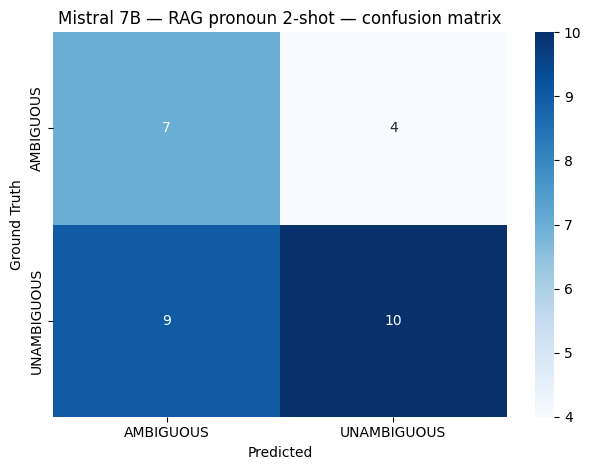

0.5666666666666667

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")

Prompt 7 - Chain-of-thought v1 (4 steps)

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.

Examples:
{examples_block}

Analyse this requirement step by step:
"{req}"

Step 1 - Pronouns: List any pronouns (it/they/this/their). For each, is the referent 100% clear?
Step 2 - Vague terms: List any terms with no measurable threshold (e.g. "quickly", "appropriate").
Step 3 - Interpretations: Could two engineers build different things and both be correct?
Step 4 - Verdict: Only if Step 1, 2, or 3 found a REAL problem → AMBIGUOUS, otherwise → UNAMBIGUOUS.


Examples:
{examples_block}

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:53:38<00:00, 227.28s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.7000

              precision    recall  f1-score   support

   AMBIGUOUS       0.67      0.36      0.47        11
 UNAMBIGUOUS       0.71      0.89      0.79        19

    accuracy                           0.70        30
   macro avg       0.69      0.63      0.63        30
weighted avg       0.69      0.70      0.67        30



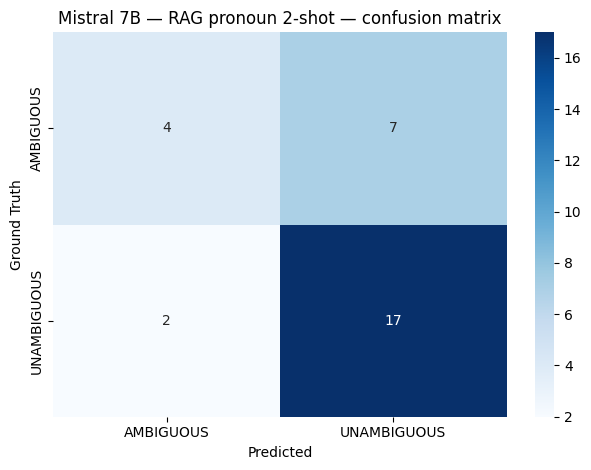

0.7

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")

In [ ]:
# Load your best results so far
df = pd.read_csv("dev_results_mistral7b_rag.csv")
clean = df[df["predicted"].isin(["AMBIGUOUS", "UNAMBIGUOUS"])].copy()
clean["correct"] = (clean["predicted"] == clean["ground_truth"].str.upper())

# Print the wrong predictions — are they actually hard?
errors = clean[~clean["correct"]]
print(f"Wrong predictions: {len(errors)}")
print("\n--- FALSE POSITIVES (predicted AMBIGUOUS, actually UNAMBIGUOUS) ---")
for _, row in errors[errors["predicted"] == "AMBIGUOUS"].iterrows():
    print(f"\nREQ: {row['requirement']}")
    print(f"EXPLANATION: {row['explanation']}")

print("\n--- FALSE NEGATIVES (predicted UNAMBIGUOUS, actually AMBIGUOUS) ---")
for _, row in errors[errors["predicted"] == "UNAMBIGUOUS"].iterrows():
    print(f"\nREQ: {row['requirement']}")
    print(f"EXPLANATION: {row['explanation']}")

Wrong predictions: 9

--- FALSE POSITIVES (predicted AMBIGUOUS, actually UNAMBIGUOUS) ---

REQ: The IETIS will support the processing of, and access to, data downloaded from the on-board HUMS and the transfer back to the HUMS of required set-up data. It will be able to accept additional data from users, as required by the HUMS functionality.
EXPLANATION: The requirement is ambiguous as it does not clearly state what data the IETIS will accept from users, and for what purpose.

REQ: Examples include: (HD) The ERMS should be able to capture records which are composed of more than one component, retaining a closely bound relationship between all components, so that they are managed as a single record.
EXPLANATION: nan

--- FALSE NEGATIVES (predicted UNAMBIGUOUS, actually AMBIGUOUS) ---

REQ: The Operational radio shall comply with the basic standards defined for all EIRENE mobile equipment in section 4.3 and this section. The Operational radio is specified to allow its use in the operatin

Prompt 8 - Chain-of-thought v2 (expanded vague term list )

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.


Analyse this requirement step by step:
"{req}"

Step 1 - Pronouns: List any pronouns (it/they/this/their/him/his).
         Is the referent 100% clear with no other possible noun? If unclear → flag it.

Step 2 - Vague terms: List any terms with no measurable threshold.
         These include obvious ones (quickly, soon, efficiently) BUT ALSO:
         - Quality terms: "adequate", "effective", "maximize", "appropriate", "sufficient"
         - Subjective terms: "simple", "affordable", "durable", "robust", "user-friendly"
         - Undefined references: "as specified", "as required", "as defined" (without a clear pointer)

Step 3 - Interpretations: Could two engineers make different design decisions and both satisfy this requirement?

Step 4 - Verdict: If ANY of the above found a real problem → AMBIGUOUS, otherwise → UNAMBIGUOUS.

Examples:
{examples_block}

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:46:49<00:00, 213.65s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.6667

              precision    recall  f1-score   support

   AMBIGUOUS       0.54      0.64      0.58        11
 UNAMBIGUOUS       0.76      0.68      0.72        19

    accuracy                           0.67        30
   macro avg       0.65      0.66      0.65        30
weighted avg       0.68      0.67      0.67        30



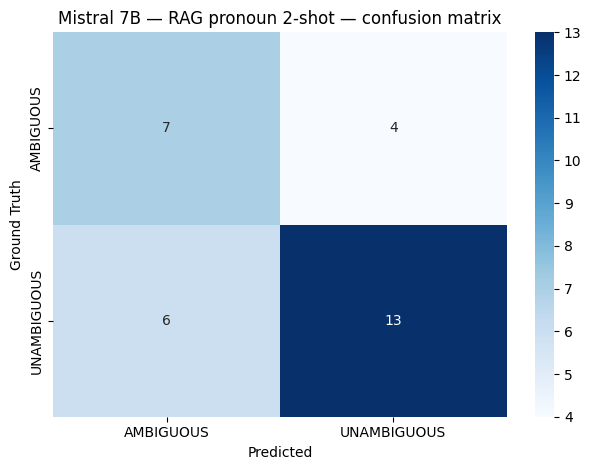

0.6666666666666666

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")

Prompt 9 - Q&A yes/no format

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.


Analyse this requirement step by step:
"{req}"

Q1: Does it contain a pronoun (it/they/this/his) with an unclear referent? yes/no
Q2: Does it contain an unmeasurable term (quickly/adequate/maximize/sufficient/as specified/as required)? yes/no
Q3: Does it contain any subjective terms like (simple/affordable/durable/robust/user-friendly)? yes/no
Q3: Could two engineers build different things and both be correct? yes/no

If any answer is yes → ambiguous. Otherwise → unambiguous.
Examples:
{examples_block}

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:20:15<00:00, 160.50s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.5333

              precision    recall  f1-score   support

   AMBIGUOUS       0.43      0.91      0.59        11
 UNAMBIGUOUS       0.86      0.32      0.46        19

    accuracy                           0.53        30
   macro avg       0.65      0.61      0.52        30
weighted avg       0.70      0.53      0.51        30



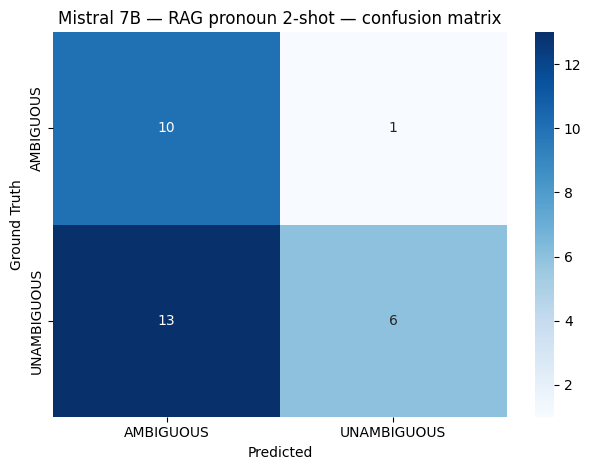

0.5333333333333333

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")

Prompt 10 - CoT v2 + 4-shot examples

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.


Analyse this requirement step by step:
"{req}"

Step 1 - Pronouns: List any pronouns (it/they/this/their/him/his).
         Is the referent 100% clear with no other possible noun? If unclear → flag it.

Step 2 - Vague terms: List any terms with no measurable threshold.
         These include obvious ones (quickly, soon, efficiently) BUT ALSO:
         - Quality terms: "adequate", "effective", "maximize", "appropriate", "sufficient"
         - Subjective terms: "simple", "affordable", "durable", "robust", "user-friendly"
         - Undefined references: "as specified", "as required", "as defined" (without a clear pointer)

Step 3 - Interpretations: Could two engineers make different design decisions and both satisfy this requirement?

Step 4 - Verdict: If ANY of the above found a real problem → AMBIGUOUS, otherwise → UNAMBIGUOUS.

Examples:
{examples_block}

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=30, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=4
)

Encoding all query requirements...


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 30/30 [1:56:26<00:00, 232.88s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.4667

              precision    recall  f1-score   support

   AMBIGUOUS       0.27      0.27      0.27        11
 UNAMBIGUOUS       0.58      0.58      0.58        19

    accuracy                           0.47        30
   macro avg       0.43      0.43      0.43        30
weighted avg       0.47      0.47      0.47        30



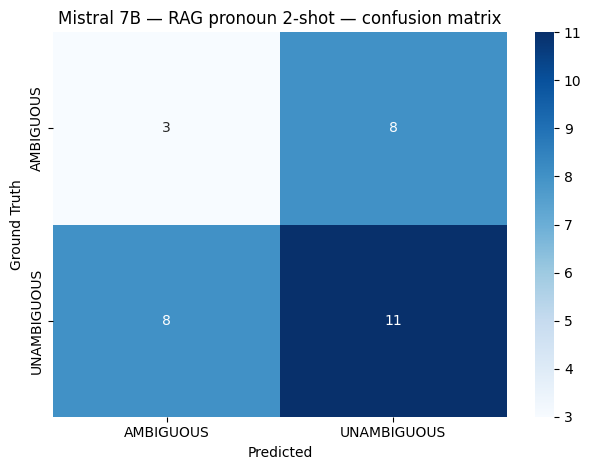

0.4666666666666667

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")

BM25 - BM25 retrieval + CoT

In [ ]:
!pip install rank-bm25 -q

In [ ]:
from rank_bm25 import BM25Okapi
from tqdm import tqdm
import numpy as np
import pandas as pd

# ── Build BM25 index once (outside the function) ────────────
tokenized_pool = [req.lower().split() for req in examples_df["requirement"]]
bm25 = BM25Okapi(tokenized_pool)
print(f"BM25 index built on {len(tokenized_pool)} requirements")

def run_evaluation_bm25(dataset_df, model_type: str, model_name: str, n_examples: int = 4):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # ── No encoding needed — BM25 is pure keyword matching ──
    results = []
    counts = {"TP": 0, "TN": 0, "FP": 0, "FN": 0, "ERROR": 0}

    def update_counts(predicted, ground_truth):
        gt = ground_truth.strip().upper()
        pr = predicted.strip().upper()
        if pr == "ERROR":                                        counts["ERROR"] += 1
        elif pr == "AMBIGUOUS"   and gt == "AMBIGUOUS":         counts["TP"] += 1
        elif pr == "UNAMBIGUOUS" and gt == "UNAMBIGUOUS":       counts["TN"] += 1
        elif pr == "AMBIGUOUS"   and gt == "UNAMBIGUOUS":       counts["FP"] += 1
        elif pr == "UNAMBIGUOUS" and gt == "AMBIGUOUS":         counts["FN"] += 1

    def print_live_stats(i):
        total   = i + 1
        correct = counts["TP"] + counts["TN"]
        acc     = correct / total if total > 0 else 0
        amb_recall   = counts["TP"] / (counts["TP"] + counts["FN"]) if (counts["TP"] + counts["FN"]) > 0 else 0
        unamb_recall = counts["TN"] / (counts["TN"] + counts["FP"]) if (counts["TN"] + counts["FP"]) > 0 else 0
        print(f"\n{'─'*45}")
        print(f"  Progress     : {total}/{len(requirements)}")
        print(f"  Accuracy     : {acc:.2f}  ({correct}/{total} correct)")
        print(f"  AMBIG  recall: {amb_recall:.2f}  (TP={counts['TP']} FN={counts['FN']})")
        print(f"  UNAMB  recall: {unamb_recall:.2f}  (TN={counts['TN']} FP={counts['FP']})")
        print(f"  Errors       : {counts['ERROR']}")
        print(f"  Confusion:")
        print(f"                 Pred AMBIG  Pred UNAMB")
        print(f"  True AMBIG  :     {counts['TP']:4d}        {counts['FN']:4d}")
        print(f"  True UNAMB  :     {counts['FP']:4d}        {counts['TN']:4d}")
        print(f"{'─'*45}\n")

    pbar = tqdm(total=len(requirements), desc="BM25 + LLM")

    for i, (req, label) in enumerate(zip(requirements, labels)):

        # ── BM25 retrieval — balanced ────────────────────────
        tokens = req.lower().split()
        scores = bm25.get_scores(tokens)
        sorted_indices = scores.argsort()[::-1]

        amb_indices   = [idx for idx in sorted_indices
                         if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        unamb_indices = [idx for idx in sorted_indices
                         if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]
        similar = examples_df.iloc[amb_indices + unamb_indices]
        # ────────────────────────────────────────────────────

        try:
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are a software requirements expert.

Analyse this requirement step by step:
"{req}"

Step 1 - Pronouns: List any pronouns (it/they/this/their/him/his).
         Is the referent 100% clear with no other possible noun? If unclear → flag it.

Step 2 - Vague terms: List any terms with no measurable threshold.
         These include obvious ones (quickly, soon, efficiently) BUT ALSO:
         - Quality terms: "adequate", "effective", "maximize", "appropriate", "sufficient"
         - Subjective terms: "simple", "affordable", "durable", "robust", "user-friendly"
         - Undefined references: "as specified", "as required", "as defined" (without a clear pointer)

Step 3 - Interpretations: Could two engineers make different design decisions and both satisfy this requirement?

Step 4 - Verdict: If ANY of the above found a real problem → AMBIGUOUS, otherwise → UNAMBIGUOUS.

Examples:
{examples_block}

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one phrase"}}"""

            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"<|im_start|>system\nYou are an expert in software requirement analysis.<|im_end|>\n<|im_start|>user\n{prompt}<|im_end|>\n<|im_start|>assistant\n"
                stop_tokens = ["<|im_end|>", "<|im_start|>"]
            elif model_type == "llama":
                full_prompt = f"<|begin_of_text|><|start_header_id|>system<|end_header_id|>\nYou are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>\n{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n"
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(full_prompt, max_tokens=120, temperature=0.0, stop=stop_tokens, echo=False)
            raw = out["choices"][0]["text"].strip()

            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed      = json.loads(match.group())
                lbl         = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence  = float(parsed.get("confidence", 0.0))
                final_label = "UNAMBIGUOUS" if "unambiguous" in lbl else ("AMBIGUOUS" if "ambiguous" in lbl else "ERROR")
            else:
                raw_upper   = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else ("AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR")
                explanation, confidence = "", 0.0

        except Exception as e:
            final_label, confidence, explanation, raw = "ERROR", 0.0, str(e), ""

        results.append({
            "requirement" : req, "ground_truth": label,
            "predicted"   : final_label, "confidence": confidence,
            "explanation" : explanation, "raw_output": raw
        })

        update_counts(final_label, label)
        acc_so_far = (counts["TP"] + counts["TN"]) / (i + 1)
        pbar.set_postfix({"acc": f"{acc_so_far:.2f}", "TP": counts["TP"], "TN": counts["TN"], "FP": counts["FP"], "FN": counts["FN"]})
        pbar.update(1)

        if (i + 1) % 20 == 0:
            print_live_stats(i)
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_bm25.csv", index=False)

    pbar.close()
    print_live_stats(len(requirements) - 1)
    df_out = pd.DataFrame(results)
    df_out.to_csv(f"dev_results_{model_name}_bm25.csv", index=False)
    print(f"Saved. Errors: {counts['ERROR']}")
    return df_out

BM25 index built on 110 requirements



BM25 + LLM:  67%|██████▋   | 20/30 [1:22:57<40:12, 241.22s/it, acc=0.60, TP=4, TN=8, FP=6, FN=2]


─────────────────────────────────────────────
  Progress     : 20/30
  Accuracy     : 0.60  (12/20 correct)
  AMBIG  recall: 0.67  (TP=4 FN=2)
  UNAMB  recall: 0.57  (TN=8 FP=6)
  Errors       : 0
  Confusion:
                 Pred AMBIG  Pred UNAMB
  True AMBIG  :        4           2
  True UNAMB  :        6           8
─────────────────────────────────────────────




BM25 + LLM: 100%|██████████| 30/30 [2:04:23<00:00, 248.78s/it, acc=0.47, TP=4, TN=10, FP=9, FN=7]



─────────────────────────────────────────────
  Progress     : 30/30
  Accuracy     : 0.47  (14/30 correct)
  AMBIG  recall: 0.36  (TP=4 FN=7)
  UNAMB  recall: 0.53  (TN=10 FP=9)
  Errors       : 0
  Confusion:
                 Pred AMBIG  Pred UNAMB
  True AMBIG  :        4           7
  True UNAMB  :        9          10
─────────────────────────────────────────────

Saved. Errors: 0

========== Mistral 7B — BM25 4-shot ==========
Valid predictions : 30
Errors            : 0

Accuracy: 0.4667

              precision    recall  f1-score   support

   AMBIGUOUS       0.31      0.36      0.33        11
 UNAMBIGUOUS       0.59      0.53      0.56        19

    accuracy                           0.47        30
   macro avg       0.45      0.44      0.44        30
weighted avg       0.49      0.47      0.47        30



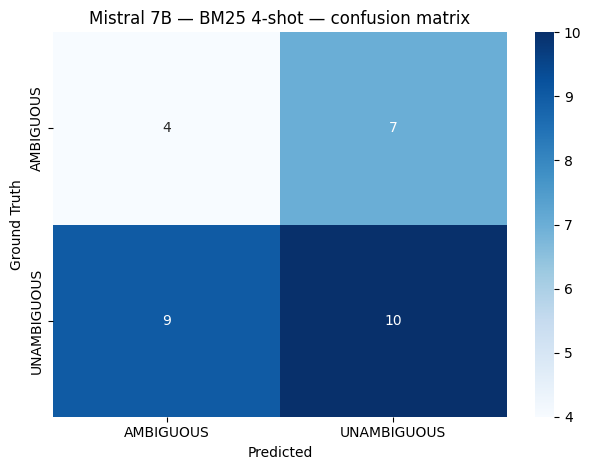

0.4666666666666667

In [ ]:
eval_sample = eval_df.sample(n=30, random_state=42)
results_bm25 = run_evaluation_bm25(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=4
)
evaluate_results(results_bm25, "Mistral 7B — BM25 4-shot")

prompt 8-100

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.


Analyse this requirement step by step:
"{req}"

Step 1 - Pronouns: List any pronouns (it/they/this/their/him/his).
         Is the referent 100% clear with no other possible noun? If unclear → flag it.

Step 2 - Vague terms: List any terms with no measurable threshold.
         These include obvious ones (quickly, soon, efficiently) BUT ALSO:
         - Quality terms: "adequate", "effective", "maximize", "appropriate", "sufficient"
         - Subjective terms: "simple", "affordable", "durable", "robust", "user-friendly"
         - Undefined references: "as specified", "as required", "as defined" (without a clear pointer)

Step 3 - Interpretations: Could two engineers make different design decisions and both satisfy this requirement?

Step 4 - Verdict: If ANY of the above found a real problem → AMBIGUOUS, otherwise → UNAMBIGUOUS.

Examples:
{examples_block}

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=100, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 100/100 [6:03:14<00:00, 217.94s/it]

Done. Errors: 0



========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 100
Errors            : 0

Accuracy: 0.5100

              precision    recall  f1-score   support

   AMBIGUOUS       0.46      0.49      0.47        45
 UNAMBIGUOUS       0.56      0.53      0.54        55

    accuracy                           0.51       100
   macro avg       0.51      0.51      0.51       100
weighted avg       0.51      0.51      0.51       100



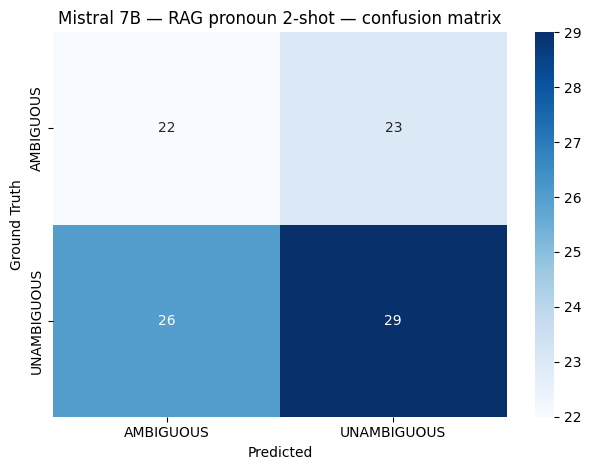

0.51

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")

prompt 7 - 100

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []

    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"

            prompt = f"""You are an expert in software requirement analysis.

Examples:
{examples_block}

Analyse this requirement step by step:
"{req}"

Step 1 - Pronouns: List any pronouns (it/they/this/their). For each, is the referent 100% clear?
Step 2 - Vague terms: List any terms with no measurable threshold (e.g. "quickly", "appropriate").
Step 3 - Interpretations: Could two engineers build different things and both be correct?
Step 4 - Verdict: Only if Step 1, 2, or 3 found a REAL problem → AMBIGUOUS, otherwise → UNAMBIGUOUS.


Examples:
{examples_block}

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "confidence": 0.0, "explanation": "one sentence"}}"""

            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=100, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=2
)

Encoding all query requirements...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 100/100 [6:34:37<00:00, 236.77s/it]

Done. Errors: 1



========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 99
Errors            : 1

Accuracy: 0.6061

              precision    recall  f1-score   support

   AMBIGUOUS       0.57      0.45      0.51        44
 UNAMBIGUOUS       0.62      0.73      0.67        55

    accuracy                           0.61        99
   macro avg       0.60      0.59      0.59        99
weighted avg       0.60      0.61      0.60        99



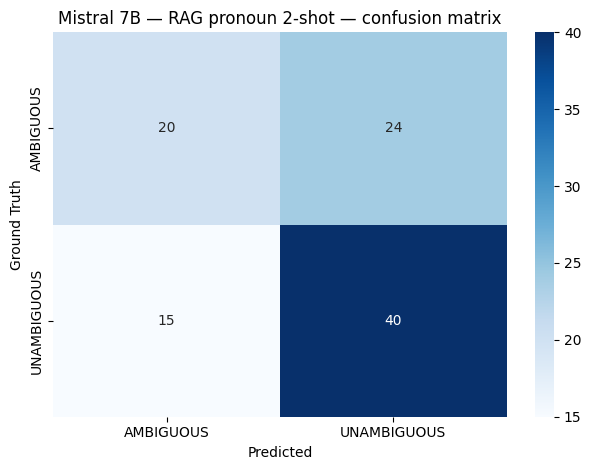

0.6060606060606061

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")

Prompt 11 - Ambiguity taxonomy 6-shot

In [ ]:
AMBIGUITY_TAXONOMY = """\
Types of ambiguity in software requirements:

1. PRONOUN AMBIGUITY
   Pronouns (it, they, their, its, this, these) whose referents are unclear.
   Example: "The system shall notify the user when it detects an error." → What does 'it' refer to?

2. VAGUE / WEAK LANGUAGE
   Words like 'fast', 'easy', 'appropriate', 'sufficient', 'adequate', 'user-friendly',
   'simple', 'flexible', 'robust' that have no measurable definition.
   Example: "The system shall respond quickly." → How quickly?

3. MISSING SUBJECT / ACTOR
   It is unclear WHO or WHAT performs an action.
   Example: "Errors shall be logged." → Logged by whom? When?

4. COORDINATION AMBIGUITY
   'and' / 'or' that can be grouped in multiple ways.
   Example: "The system shall support PDF and Word or Excel exports." → (PDF and Word) or Excel? or PDF and (Word or Excel)?

5. SCOPE / QUANTIFIER AMBIGUITY
   Unclear scope: 'all', 'each', 'any', 'every', 'some', 'most'.
   Example: "Each user shall have access to all reports." → Does 'all' include restricted reports?

6. TEMPORAL AMBIGUITY
   Unclear timing: 'when', 'after', 'before', 'during', 'immediately' with no defined threshold.
   Example: "The system shall update the record after approval." → How long after?

7. CONDITIONAL AMBIGUITY
   Conditions that can be interpreted in multiple ways.
   Example: "If the user is logged in and idle or disconnected, the session shall expire."

8. NEGATION AMBIGUITY
   Negations that create unclear scope.
   Example: "The system shall not allow users without admin rights and supervisors to delete records."
"""

In [ ]:
# Instead of encoding one requirement at a time inside the loop
# encode ALL query requirements upfront in one batch

from tqdm import tqdm
import numpy as np
import pandas as pd

def run_evaluation_rag_fast(dataset_df, model_type: str, model_name: str, n_examples: int = 5):

    requirements = dataset_df["requirement"].tolist() if "requirement" in dataset_df.columns else dataset_df["Context"].tolist()
    labels = dataset_df["label"].tolist() if "label" in dataset_df.columns else dataset_df["DetectedAs"].tolist()

    # Encode ALL queries in one batch — much faster than one by one
    print("Encoding all query requirements...")
    query_embeddings = embedder.encode(
        requirements,
        batch_size=32,
        show_progress_bar=True
    )

    # Compute ALL similarities at once — matrix operation
    print("Computing similarities...")
    all_similarities = np.dot(query_embeddings, example_embeddings.T)
    # Shape: (n_queries, n_examples) — each row is similarities for one query

    results = []
    for i, (req, label) in enumerate(tqdm(zip(requirements, labels), total=len(requirements))):
        # # Get top-k indices for this query — no embedding needed, already computed
        sim_scores = all_similarities[i]
        top_indices = sim_scores.argsort()[-n_examples:][::-1]
        similar = examples_df.iloc[top_indices]
        # balanced retrieval ───────────
        # sorted_indices = sim_scores.argsort()[::-1]

        # amb_indices   = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "AMBIGUOUS"][:n_examples//2]
        # unamb_indices = [idx for idx in sorted_indices
        #                 if examples_df.iloc[idx]["label"].upper() == "UNAMBIGUOUS"][:n_examples//2]

        # similar = examples_df.iloc[amb_indices + unamb_indices]

        try:
            # Build prompt with retrieved examples
            examples_block = ""
            for _, row in similar.iterrows():
                lbl = row["label"].strip().capitalize()
                examples_block += f"Requirement: {row['requirement']}\nClassification: {lbl}\n\n"
            prompt = f"""You are an expert software requirements engineer.

{AMBIGUITY_TAXONOMY}

NOTE: Passive voice is STANDARD in requirements — do NOT flag it.
Technical acronyms are NOT ambiguous on their own.

Examples:
{examples_block}

Requirement: "{req}"

Before classifying ask: can I point to one specific word that would cause
two developers to implement this differently? If yes → ambiguous. If no → unambiguous.

Return ONLY JSON:
{{"classification": "ambiguous or unambiguous", "ambiguity_type": "pronoun/vague_language/missing_actor/coordination/scope/temporal/none", "explanation": "one sentence"}}"""
            # Wrap in model format
            if model_type in ["qwen", "eurollm", "mistral7b", "croissant"]:
                full_prompt = f"""<|im_start|>system
You are an expert in software requirement analysis.<|im_end|>
<|im_start|>user
{prompt}<|im_end|>
<|im_start|>assistant
"""
                stop_tokens = ["<|im_end|>", "<|im_start|>"]

            elif model_type == "llama":
                full_prompt = f"""<|begin_of_text|><|start_header_id|>system<|end_header_id|>
You are an expert in software requirement analysis.<|eot_id|><|start_header_id|>user<|end_header_id|>
{prompt}<|eot_id|><|start_header_id|>assistant<|end_header_id|>
"""
                stop_tokens = ["<|eot_id|>", "<|start_header_id|>"]

            out = llm(
                full_prompt,
                max_tokens=100,   # reduced from 120
                temperature=0.0,
                stop=stop_tokens,
                echo=False
            )

            raw = out["choices"][0]["text"].strip()

            # Parse JSON
            import json, re
            match = re.search(r'\{.*?\}', raw, re.DOTALL)
            if match:
                parsed = json.loads(match.group())
                lbl = parsed.get("classification", "ERROR").strip().lower()
                explanation = parsed.get("explanation", "")
                confidence = float(parsed.get("confidence", 0.0))
                if "unambiguous" in lbl:
                    final_label = "UNAMBIGUOUS"
                elif "ambiguous" in lbl:
                    final_label = "AMBIGUOUS"
                else:
                    final_label = "ERROR"
            else:
                raw_upper = raw.upper()
                final_label = "UNAMBIGUOUS" if "UNAMBIGUOUS" in raw_upper else \
                              "AMBIGUOUS" if "AMBIGUOUS" in raw_upper else "ERROR"
                explanation = ""
                confidence = 0.0

            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : final_label,
                "confidence"   : confidence,
                "explanation"  : explanation,
                "raw_output"   : raw
            })

        except Exception as e:
            results.append({
                "requirement"  : req,
                "ground_truth" : label,
                "predicted"    : "ERROR",
                "confidence"   : 0.0,
                "explanation"  : str(e),
                "raw_output"   : ""
            })

        # Checkpoint every 20
        if (i + 1) % 20 == 0:
            pd.DataFrame(results).to_csv(f"checkpoint_{model_name}_rag.csv", index=False)

    df = pd.DataFrame(results)
    df.to_csv(f"dev_results_{model_name}_rag.csv", index=False)
    print(f"Done. Errors: {(df['predicted'] == 'ERROR').sum()}")
    return df

In [ ]:
# If columns are "Context" and "DetectedAs" rename first
prompt_dev_df = prompt_dev_df.rename(columns={
    "Context"    : "requirement",
    "DetectedAs" : "label"
})

eval_sample = eval_df.sample(n=100, random_state=42)

dev_results_rag_pronoun = run_evaluation_rag_fast(
    eval_sample,
    model_type="qwen",
    model_name="mistral7b",
    n_examples=6
)

Encoding all query requirements...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Computing similarities...


100%|██████████| 100/100 [6:23:44<00:00, 230.24s/it]

Done. Errors: 7



========== Mistral 7B — RAG pronoun 6-shot ==========
Valid predictions : 93
Errors            : 7

Accuracy: 0.5376

              precision    recall  f1-score   support

   AMBIGUOUS       0.53      1.00      0.69        48
 UNAMBIGUOUS       1.00      0.04      0.09        45

    accuracy                           0.54        93
   macro avg       0.76      0.52      0.39        93
weighted avg       0.76      0.54      0.40        93



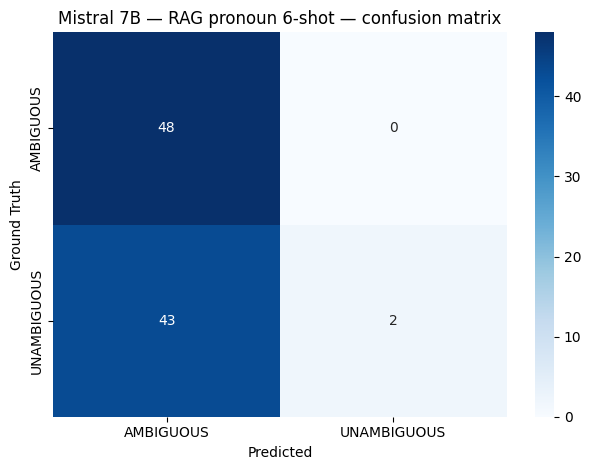

0.5376344086021505

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 6-shot")


========== Mistral 7B — RAG pronoun 2-shot ==========
Valid predictions : 99
Errors            : 1

Accuracy: 0.5960

              precision    recall  f1-score   support

   AMBIGUOUS       0.53      0.77      0.63        44
 UNAMBIGUOUS       0.71      0.45      0.56        55

    accuracy                           0.60        99
   macro avg       0.62      0.61      0.59        99
weighted avg       0.63      0.60      0.59        99



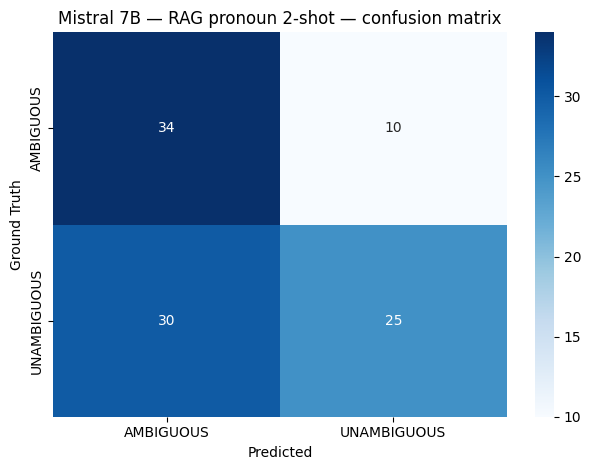

0.5959595959595959

In [ ]:
evaluate_results(dev_results_rag_pronoun, "Mistral 7B — RAG pronoun 2-shot")